# 📘 Módulo 27: El Algoritmo K-Means

Hola, deseamos darte la bienvenida al módulo **El Algoritmo K-Means** del curso Profesión Científico de Datos.

En este módulo, exploraremos el algoritmo de agrupamiento K-Means, una técnica esencial de aprendizaje no supervisado para clasificar datos en grupos basados en la similitud de las observaciones. Este método es ampliamente utilizado en diversas aplicaciones, como el análisis de mercado y la física, para identificar nichos de oportunidad y diferencias significativas entre grupos.

### 🎯 Objetivos de Aprendizaje

1. **Implementación del Algoritmo K-Means:**
   Aprenderás a implementar el algoritmo en dos pasos fundamentales: representar cada grupo por su centroide y asignar cada observación al centroide más cercano. Este proceso se repite iterativamente hasta lograr una agrupación estable.

2. **Determinación del Número Óptimo de Clusters (K):**
   Exploraremos métodos matemáticos y visuales como el **Gráfico del Codo (Elbow Method)** y el **Índice de Silueta (Silhouette Score)** para determinar el número óptimo de clústers, asegurando una agrupación efectiva y significativa.

3. **Visualización, Análisis de Datos y Reducción de Dimensionalidad:**
   Utilizaremos herramientas como Pandas, Matplotlib, Seaborn y Scikit-learn para manejar y visualizar los datos. Además, analizaremos el impacto del **PCA (Análisis de Componentes Principales)** en la agrupación de datos.

## 📖 1. Teoría: Conociendo el Algoritmo K-Medias

El algoritmo K-Means busca particionar $n$ observaciones en $k$ clústers, donde cada observación pertenece al clúster cuyo valor medio (centroide) es el más cercano. 

### ¿Cómo funciona internamente?
1. **Inicialización:** Se eligen $k$ puntos aleatorios como centroides iniciales.
2. **Asignación:** Cada punto de los datos se asigna al centroide más cercano (usualmente minimizando la distancia euclidiana).
3. **Actualización:** Se recalcula la posición de los centroides tomando el promedio de los puntos asignados a cada clúster.
4. **Iteración:** Los pasos 2 y 3 se repiten hasta que los centroides no cambian o se alcanza el número máximo de iteraciones.

### Evaluando el Modelo: ¿Cómo elegir K?
Como es aprendizaje no supervisado, no tenemos etiquetas para calcular el "Accuracy". En su lugar, usamos:
* **Método del Codo (Inercia / WCSS):** Mide la suma de las distancias al cuadrado de las muestras a su centroide más cercano. Buscamos el punto donde la curva deja de caer drásticamente (el "codo").
* **Índice de Silueta:** Evalúa qué tan similar es un objeto a su propio clúster en comparación con otros clústers. Varía de -1 a 1, donde un valor más cercano a 1 indica una mejor agrupación.

In [5]:
# 🛠️ Configuración inicial e importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings

# Ocultar todas las advertencias
warnings.filterwarnings('ignore')
# Configuración visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 💻 2. Práctica: Agrupación K-Medias Dataset Iris

**El Reto:**
1. Extraer en línea la base de datos “Iris.csv”.
2. Agrupar las observaciones mediante K-Medias sin transformar los datos. Determinar el número óptimo de clusters (Codo y Silhouette).
3. Repetir el ejercicio tras reducir la dimensionalidad a 2 componentes mediante PCA.
4. Comparar resultados.

In [2]:
# --- PASO 1: Extracción de datos en línea ---
# Extraemos el dataset clásico de Iris directamente de un repositorio de Seaborn/GitHub
url_iris = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df_iris_raw = pd.read_csv(url_iris)

# Visualizamos las primeras filas
display(df_iris_raw.head())

# Separamos las características numéricas de la variable objetivo real 
# (Ignoraremos la columna 'species' para el K-Means, ya que es aprendizaje NO supervisado)
X_raw = df_iris_raw.drop(columns=['species'])


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### 2.1 Determinación del Número Óptimo de Clústers (Datos Originales)

Para agrupar correctamente, primero debemos iterar el algoritmo K-Means evaluando $k$ de 2 a 10 y calcular la inercia (WCSS) y el índice de Silueta.

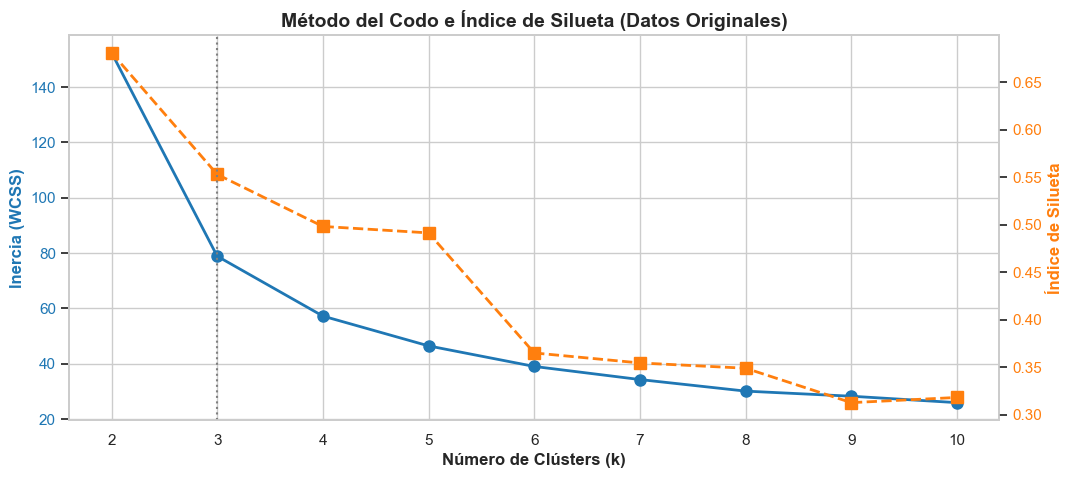

In [6]:
# --- PASO 2: Evaluación del número óptimo de K (Sin transformación) ---
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    # random_state asegura reproducibilidad, n_init es el número de inicializaciones
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_raw)
    
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_raw, kmeans_temp.labels_))

# Visualización: Gráfico del Codo vs Índice de Silueta
fig, ax1 = plt.subplots(figsize=(12, 5))

# Gráfico del Codo (Inercia)
color = 'tab:blue'
ax1.set_xlabel('Número de Clústers (k)', fontweight='bold')
ax1.set_ylabel('Inercia (WCSS)', color=color, fontweight='bold')
ax1.plot(K_range, inertias, marker='o', color=color, linewidth=2, markersize=8)
ax1.tick_params(axis='y', labelcolor=color)

# Crear un segundo eje para el Índice de Silueta
ax2 = ax1.twinx()  
color = 'tab:orange'
ax2.set_ylabel('Índice de Silueta', color=color, fontweight='bold')  
ax2.plot(K_range, silhouette_scores, marker='s', color=color, linewidth=2, markersize=8, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Método del Codo e Índice de Silueta (Datos Originales)', fontsize=14, fontweight='bold')
plt.axvline(x=3, color='gray', linestyle=':', label='K Óptimo sugerido (3)')
plt.grid(False)
plt.show()

**Interpretación:**
* **Codo:** Observamos una inflexión (el codo) entre $k=2$ y $k=3$.
* **Silueta:** El pico máximo de silueta ocurre en $k=2$, pero $k=3$ mantiene un puntaje muy decente. Sabiendo (por el contexto de Iris) que existen 3 especies reales, y viendo que la inercia cae significativamente al pasar a 3, **seleccionaremos $k=3$**.

A continuación, aplicamos K-Means definitivo con $k=3$ a los datos crudos.

In [7]:
# Aplicando K-Means definitivo a los datos originales
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10)
df_iris_raw['Cluster_Raw'] = kmeans_raw.fit_predict(X_raw)

print("Centros de los clústers (Datos Originales):")
display(pd.DataFrame(kmeans_raw.cluster_centers_, columns=X_raw.columns))

Centros de los clústers (Datos Originales):


,sepal_length,sepal_width,petal_length,petal_width
0,5.901613,2.748387,4.393548,1.433871
1,5.006000,3.428000,1.462000,0.246000
2,6.850000,3.073684,5.742105,2.071053


### 2.2 Transformación con PCA y Nuevo Agrupamiento

Antes de aplicar PCA, es una **regla innegociable** estandarizar los datos para que todas las variables tengan media 0 y varianza 1. Posteriormente, reduciremos de 4 dimensiones a 2 y repetiremos K-Means.

Varianza explicada por los 2 componentes: 95.81%



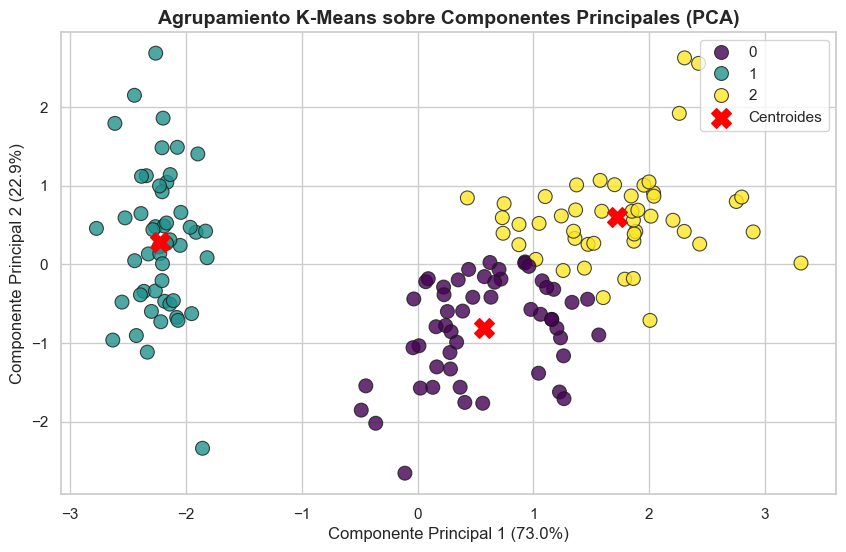

In [8]:
# --- PASO 3: Reducción de Dimensionalidad (PCA) y K-Means ---

# 1. Estandarización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 2. Aplicación de PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Varianza explicada por los 2 componentes: {sum(pca.explained_variance_ratio_) * 100:.2f}%\n")

# 3. K-Means sobre las 2 dimensiones del PCA (usaremos k=3 directamente basándonos en el análisis anterior)
kmeans_pca = KMeans(n_clusters=3, random_state=42, n_init=10)
df_iris_raw['Cluster_PCA'] = kmeans_pca.fit_predict(X_pca)

# --- Visualización de los resultados en 2D ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=df_iris_raw['Cluster_PCA'], 
    palette='viridis', 
    s=100, 
    alpha=0.8,
    edgecolor='k'
)

# Graficando los centroides
centroides_pca = kmeans_pca.cluster_centers_
plt.scatter(
    centroides_pca[:, 0], centroides_pca[:, 1], 
    c='red', s=200, marker='X', label='Centroides'
)

plt.title('Agrupamiento K-Means sobre Componentes Principales (PCA)', fontsize=14, fontweight='bold')
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend()
plt.show()

### 2.3 Comparación de Resultados (Inciso 2 vs Inciso 3)

Al comparar el agrupamiento sobre datos originales versus datos reducidos por PCA:

1. **¿Se obtuvieron los mismos resultados?** 
   Los resultados son altamente consistentes, pero no idénticos. El PCA filtra el "ruido" al enfocarse en las direcciones de mayor varianza, lo que a menudo "limpia" las fronteras entre clústers.
2. **Ventaja práctica del PCA antes de K-Means:**
   * **Interpretación Visual:** Podemos graficar la separación de grupos en un plano 2D comprensible humano, capturando (en este caso) casi el 96% de la información original.
   * **Maldición de la Dimensionalidad:** El cálculo de la distancia Euclidiana en K-Means pierde eficacia en espacios de altísima dimensión. PCA reduce estas dimensiones, mejorando matemáticamente el cálculo de distancias.
   * **Rendimiento Computacional:** Con datasets masivos (millones de registros, cientos de features), reducir columnas acelera drásticamente el tiempo de ejecución del algoritmo.

## 🚀 3. Versión Pro: Llevando K-Means a Producción

En entornos de producción, no ejecutamos scripts sueltos. Usamos **Pipelines**, **Programación Orientada a Objetos (POO)** y validaciones robustas. A continuación, presento cómo se estructuraría este mismo ejercicio utilizando buenas prácticas, integración continua con Scikit-learn y tipado estático (Type Hinting).

In [10]:
from sklearn.pipeline import Pipeline
from typing import Tuple, Dict, Any
import logging

# Configuración básica de logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

class KMeansRecommenderPro:
    """
    Clase de producción para modelado de clústers integrando Scaling, PCA y K-Means.
    """
    def __init__(self, n_clusters: int, use_pca: bool = True, n_components: int = 2, random_state: int = 42):
        self.n_clusters = n_clusters
        self.use_pca = use_pca
        self.n_components = n_components
        self.random_state = random_state
        self.pipeline = self._build_pipeline()
        
    def _build_pipeline(self) -> Pipeline:
        """Construye el pipeline de Scikit-Learn basado en la configuración."""
        steps = [('scaler', StandardScaler())]
        
        if self.use_pca:
            steps.append(('pca', PCA(n_components=self.n_components, random_state=self.random_state)))
            
        steps.append(('kmeans', KMeans(n_clusters=self.n_clusters, random_state=self.random_state, n_init='auto')))
        return Pipeline(steps)
    
    def fit_predict(self, X: pd.DataFrame) -> np.ndarray:
        """Ajusta el pipeline y retorna las asignaciones de clúster."""
        logging.info(f"Iniciando entrenamiento. Dimensiones de entrada: {X.shape}")
        try:
            labels = self.pipeline.fit_predict(X)
            logging.info("Entrenamiento finalizado exitosamente.")
            return labels
        except Exception as e:
            logging.error(f"Error durante el modelado: {e}")
            raise

    def get_metrics(self, X: pd.DataFrame, labels: np.ndarray) -> Dict[str, Any]:
        """Calcula métricas clave del modelo en producción."""
        # Calculamos la silueta considerando si se usó PCA o no
        X_processed = self.pipeline[:-1].transform(X) if len(self.pipeline.steps) > 1 else X
        sil_score = silhouette_score(X_processed, labels)
        inertia = self.pipeline.named_steps['kmeans'].inertia_
        
        metrics = {
            'Silhouette_Score': round(sil_score, 4),
            'Inertia': round(inertia, 2)
        }
        logging.info(f"Métricas calculadas: {metrics}")
        return metrics

# -----------------------------------------------------
# 🧪 Uso en Producción (Simulación)
# -----------------------------------------------------
if __name__ == "__main__":
    # Instanciamos el modelo con 3 clústers
    modelo_prod = KMeansRecommenderPro(n_clusters=3, use_pca=True)
    
    # Predecimos y extraemos métricas de forma limpia
    df_iris_raw['Cluster_Prod'] = modelo_prod.fit_predict(X_raw)
    metricas_modelo = modelo_prod.get_metrics(X_raw, df_iris_raw['Cluster_Prod'])
    
    print("\nResultados encapsulados listos para exportar a un microservicio:")
    print(metricas_modelo)

2026-09-30 13:56:56,579 - INFO - Iniciando entrenamiento. Dimensiones de entrada: (150, 4)
2026-09-30 13:56:56,584 - INFO - Entrenamiento finalizado exitosamente.
2026-09-30 13:56:56,590 - INFO - Métricas calculadas: {'Silhouette_Score': np.float64(0.5228), 'Inertia': 166.04}



Resultados encapsulados listos para exportar a un microservicio:
{'Silhouette_Score': np.float64(0.5228), 'Inertia': 166.04}


## 📚 4. Glosario (Módulo 27)

Recuerda los términos más utilizados durante el módulo:

* **Centroide:** El punto que representa el centro de un clúster en el algoritmo K-means, calculado como el promedio de todas las observaciones en el clúster.
* **Clúster:** Un grupo de datos que son similares entre sí, formado durante el proceso de agrupamiento en el algoritmo K-means.
* **Gráfico del codo (Elbow Method):** Una técnica visual utilizada para determinar el número óptimo de clústers en K-means, identificando el punto donde la reducción de la suma de las distancias al cuadrado se estabiliza.
* **Índice de silueta:** Una métrica que evalúa la calidad de un clúster comparando la similitud de un objeto con su propio clúster frente a otros clústers.
* **K-means:** Un algoritmo de agrupamiento que clasifica datos en K grupos basados en la similitud de las observaciones, optimizando la homogeneidad interna y la heterogeneidad externa.
* **Optimización:** El proceso de ajustar los parámetros del algoritmo K-means para mejorar la similitud dentro de los clústers y las diferencias entre ellos.
* **PCA (Análisis de Componentes Principales):** Un método de reducción de dimensionalidad que transforma datos de alta dimensión en un espacio de menor dimensión, facilitando la visualización y el análisis.
* **Scikit-learn:** Una biblioteca de Python utilizada para implementar el algoritmo K-means y otras técnicas de aprendizaje automático.
* **Similitud:** Una medida de cuán parecidas son las observaciones dentro de un clúster en el contexto del algoritmo K-means.
* **Visualización:** El uso de herramientas como Matplotlib y Seaborn para representar gráficamente los resultados del agrupamiento, facilitando la interpretación de los datos.

## 🎯 5. Conclusiones

1. **La Matemática tras el Agrupamiento:** K-Means es un algoritmo sumamente intuitivo que transforma el problema de "agrupar" en un problema matemático de minimización de distancias. No requiere que conozcamos las categorías con antelación, lo que lo hace invaluable para descubrir patrones ocultos.
2. **Las Métricas Complementan la Intuición:** No existe una respuesta absoluta para el valor de $K$. El cruce entre el Gráfico del Codo (Inercia) y el Índice de Silueta nos otorga una guía analítica sólida para tomar decisiones objetivas.
3. **El Papel Crítico del Preprocesamiento (PCA y Escalado):** Alimentar un K-Means con datos en diferentes escalas arruina el cálculo de distancia euclidiana. Escalar es obligatorio. Al combinarlo con PCA, no solo vencemos la maldición de la dimensionalidad optimizando recursos, sino que logramos representaciones visuales poderosas para reportar nuestros hallazgos al negocio de manera clara y digerible.
4. **Del Notebook a Producción:** Aislar lógicas estadísticas en un Pipeline, como se mostró en la versión Pro, evita fugas de datos y asegura que los nuevos usuarios que lleguen a nuestra aplicación (o nuevos productos en una tienda) sigan exactamente los mismos pasos de transformación y asignación, generando un sistema automatizado robusto.